# Stories Coffee: A Group ("Couple") Offer

**Question:** when two or more people order together, do they buy less food than they would alone, and would an offer such as *"with two drinks, a pastry at a discount"* add gross profit?

This builds on `06_bundle_offers.ipynb` (same data cleaning, same break-even logic, same forecast) but targets a different customer: the group order rather than the single customer.

Throughout, **observed facts** (computed from the data) are kept separate from **assumptions** (marked *Assumption*) and **estimates** (marked *Estimate*).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import norm

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
# Repository layout: run from the repo root or notebooks/; data comes from STORIES_DATA or data/
ROOT = Path.cwd()
if not (ROOT / "reports").exists(): ROOT = ROOT.parent
DATA = Path(os.environ.get("STORIES_DATA", ROOT / "data" / "stories_transactions.csv"))
FIG = ROOT / "figures" / "couple_offer"; FIG.mkdir(parents=True, exist_ok=True)

# One fixed colour per branch, same as 01_eda.ipynb
BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "font.size": 9, "legend.frameon": False, "lines.linewidth": 2,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Load the data

In [2]:
raw = pd.read_csv(DATA, dtype={"Customer ID": "string"})
raw = raw.rename(columns={
    "Transaction ID": "txn", "Date": "date", "Time": "time", "Branch": "branch",
    "Customer ID": "cust", "Order Type": "order_type", "Product": "product",
    "Category": "category", "Quantity": "qty", "Unit Price (USD)": "price",
    "Discount Rate": "disc", "Unit Cost (USD)": "cost",
    "Line Revenue (USD)": "rev", "Line Gross Profit (USD)": "gp"})
raw = raw[~raw.duplicated()].copy()
raw["ts"] = pd.to_datetime(raw["date"] + " " + raw["time"])
raw["date"] = pd.to_datetime(raw["date"])
raw["hour"] = raw.ts.dt.hour

DRINKS = {"Hot Coffee", "Cold Coffee", "Matcha & Tea", "Cold Drinks"}
raw["drink_units"] = np.where(raw.category.isin(DRINKS), raw.qty, 0)
raw["food_units"] = np.where(raw.category.isin(DRINKS), 0, raw.qty)
SPLIT = pd.Timestamp("2026-04-01")
raw["half"] = np.where(raw.date < SPLIT, "train", "test")

txn = raw.groupby("txn").agg(branch=("branch", "first"), date=("date", "first"), hour=("hour", "first"),
                             half=("half", "first"), order_type=("order_type", "first"),
                             lines=("product", "size"), drinks=("drink_units", "sum"), food=("food_units", "sum"),
                             rev=("rev", "sum"), gp=("gp", "sum"))
txn["cats"] = raw.groupby("txn").category.apply(set)
txn["prods"] = raw.groupby("txn")["product"].apply(set)
test_tx = txn[txn.half == "test"]
months_test = test_tx.date.dt.to_period("M").nunique()
print("line items:", len(raw), "| transactions:", len(txn), "| Apr-Jun months:", months_test)

line items: 51045 | transactions: 33887 | Apr-Jun months: 3


## 2. Do group orders buy less food?

The data has no party size. *Assumption:* a basket with **two or more drink units** was ordered for two or more people. Some will be one person buying two drinks, so this group is an approximation.

If each person in a group behaved like a one-drink customer, a two-person basket would contain food with probability `1 - (1 - p)^2`, where `p` is the food rate of one-drink baskets.

In [3]:
by_drinks = txn[txn.drinks.between(1, 3)].groupby("drinks").agg(
    baskets=("rev", "size"), with_food=("food", lambda s: (s > 0).mean()),
    food_units=("food", "mean"), ticket=("rev", "mean"))
p1 = by_drinks.loc[1, "with_food"]
by_drinks["with_food_if_independent"] = 1 - (1 - p1) ** by_drinks.index
by_drinks["share_of_baskets"] = by_drinks.baskets / len(txn)
by_drinks.round(3)

,baskets,with_food,food_units,ticket,with_food_if_independent,share_of_baskets
drinks,,,,,,
1,17849,0.468,0.523,8.376,0.468,0.527
2,4873,0.229,0.249,11.765,0.717,0.144
3,660,0.135,0.139,15.936,0.850,0.019


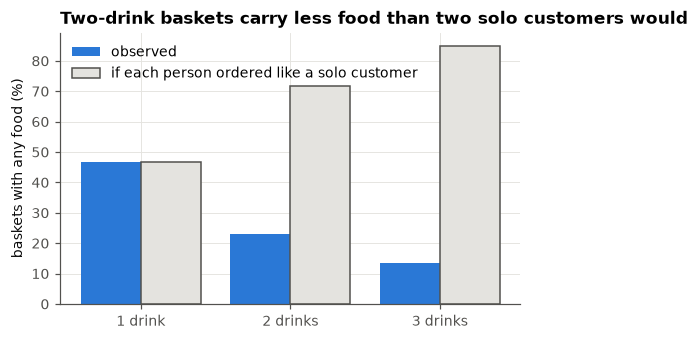

In [4]:
fig, ax = plt.subplots(figsize=(5.4, 3.2))
x = np.arange(len(by_drinks))
ax.bar(x - 0.2, by_drinks.with_food * 100, 0.4, color="#2a78d6", label="observed")
ax.bar(x + 0.2, by_drinks.with_food_if_independent * 100, 0.4, color=GRID, edgecolor=MUTED, label="if each person ordered like a solo customer")
ax.set_xticks(x, [f"{k} drink{'s' if k > 1 else ''}" for k in by_drinks.index])
ax.set_ylabel("baskets with any food (%)")
ax.set_title("Two-drink baskets carry less food than two solo customers would")
ax.legend(loc="upper left"); save(fig, "08_group_food_gap"); plt.show()

**Observed:** about half of one-drink baskets include food, but only about a quarter of two-drink baskets, against roughly 70% expected if each person ordered like a solo customer. At first sight, group orders are where food is missing.

### 2.1 Is the gap just a limit in how the data was built?

No basket has more than 3 lines, so a basket with two drink lines has room for only one food line. If that cap caused the gap, two drinks entered as **one line with quantity 2** (leaving two free lines) should carry much more food than two drinks on **two separate lines**.

In [5]:
drink_lines = raw[raw.category.isin(DRINKS)].groupby("txn").size().reindex(txn.index, fill_value=0)
two = txn[txn.drinks == 2].assign(drink_lines=drink_lines)
cap = two.groupby("drink_lines").agg(baskets=("rev", "size"), with_food=("food", lambda s: (s > 0).mean()),
                                     free_lines=("lines", lambda s: 3 - s.min()))
print("max lines in any basket:", txn.lines.max())
cap.round(3)

max lines in any basket: 3


,baskets,with_food,free_lines
drink_lines,,,
1,1046,0.487,2
2,3827,0.159,1


**Observed:** it is mostly the cap. When the two drinks sit on one line, leaving two free lines, about 49% of baskets have food, the same as solo customers. When they take two lines, leaving one free line, only about 16% do. So most of the gap comes from how this dataset was built, not from how groups buy.

What remains is smaller: even with room, a two-drink basket carries food about as often as **one** solo customer (49%), not two (about 72%). That could be a real "one pastry to share" habit, or the same generator again. Real tills have no 3-line limit, so **Stories can check this in its own till data before spending anything** (section 7).

## 3. Can group orders be targeted by time, day or branch?

In [6]:
txn["group"] = txn.drinks >= 2
band = pd.cut(txn.hour, [6, 11, 14, 17, 20, 24], labels=["7-11", "11-14", "14-17", "17-20", "20-24"], right=False)
print("share of baskets that are group orders")
print("  by time of day:", txn.groupby(band, observed=True).group.mean().round(3).to_dict())
print("  by weekday (0 = Mon):", txn.groupby(txn.date.dt.dayofweek).group.mean().round(3).to_dict())
print("  by order type:", txn.groupby("order_type").group.mean().round(3).to_dict())
print("  by branch:", txn.groupby("branch").group.mean().round(3).to_dict())

share of baskets that are group orders
  by time of day: {'7-11': 0.162, '11-14': 0.16, '14-17': 0.156, '17-20': 0.17, '20-24': 0.168}
  by weekday (0 = Mon): {0: 0.163, 1: 0.168, 2: 0.152, 3: 0.158, 4: 0.164, 5: 0.178, 6: 0.172}
  by order type: {'Dine-in': 0.169, 'Takeaway': 0.158}
  by branch: {'Garden': 0.161, 'Harbour': 0.169, 'Uptown': 0.159}


**Observed:** group orders are about 16 to 18% of baskets at every hour, day, branch and order type. There is no "couples' time" to target, so the offer has to run all day and be triggered at the till by the basket itself (two or more drinks). *Caveat:* real couples would likely cluster on evenings, weekends and dine-in; a pattern this flat is another sign of generated data.

## 4. What to offer

**Rule (fixed before looking at profit):** offer the food category that group baskets already buy most often, as long as its share among group food purchases is stable from Jan to Mar to Apr to Jun.

In [7]:
FOOD = sorted(set(raw.category) - DRINKS)
g = txn[txn.group]
mix = pd.DataFrame({h: {c: g[g.half == h].cats.map(lambda s: c in s).mean() for c in FOOD} for h in ["train", "test"]})
mix["solo_test"] = {c: txn[(txn.drinks == 1) & (txn.half == "test")].cats.map(lambda s: c in s).mean() for c in FOOD}
mix = mix.sort_values("train", ascending=False)
ADDON = mix.index[0]
print("add-on category:", ADDON)
mix.round(3)

add-on category: Bakery


,train,test,solo_test
Bakery,0.112,0.111,0.259
Sandwiches,0.035,0.035,0.080
Desserts,0.034,0.041,0.077
Breakfast,0.021,0.025,0.039
Meals,0.014,0.013,0.031


**The offer:** *with two or more drinks, one bakery item at a discount.* One item, not two, keeps it simple at the till and keeps the discount cost low. The scenario in section 5 uses 20% off, the lowest discount tested, because the break-even take-up climbs quickly above it.

### 4.1 Break-even

At a discount `d` on the bakery item's price:

- Every group basket that **already** contains a bakery item gets `d x price` off. That is pure cost. (*Assumption, worst case:* all of them use the offer.)
- Every group basket **without** bakery that adds one because of the offer adds the item's profit after discount.

The **break-even take-up** is the share of group baskets without bakery that must add one so that the gains cover the cost. Prices and costs are per branch (Garden's costs are higher).

In [8]:
test_lines = raw[raw.half == "test"]
unit = (test_lines.assign(list_rev=test_lines.qty * test_lines.price, list_gp=test_lines.qty * (test_lines.price - test_lines.cost))
        .groupby(["branch", "category"])[["qty", "list_rev", "list_gp"]].sum())
unit["price"], unit["gp"] = unit.list_rev / unit.qty, unit.list_gp / unit.qty

gt = test_tx[test_tx.drinks >= 2]
has_addon = gt.cats.map(lambda s: ADDON in s)
pool = pd.DataFrame({"already": has_addon.groupby(gt.branch).sum(), "target": (~has_addon).groupby(gt.branch).sum()}) / months_test

DISCOUNTS = [0.2, 0.3, 0.5]
rows = []
for br in BRANCHES:
    price, gp = unit.loc[(br, ADDON), ["price", "gp"]]
    for d in DISCOUNTS:
        cost = pool.loc[br, "already"] * d * price
        gain = gp - d * price
        rows.append(dict(branch=br, discount=d, item_price=price, item_gp=gp, already_per_month=pool.loc[br, "already"],
                         target_per_month=pool.loc[br, "target"], gain_per_upgrade=gain,
                         breakeven_takeup=cost / (pool.loc[br, "target"] * gain) if gain > 0 else np.inf,
                         discount_as_pct_of_group_ticket=d * price / gt[gt.branch == br].rev.mean()))
be = pd.DataFrame(rows)
be.round(3)

,branch,discount,item_price,item_gp,already_per_month,target_per_month,gain_per_upgrade,breakeven_takeup,discount_as_pct_of_group_ticket
0,Harbour,0.2,4.288,2.825,62.333,469.333,1.967,0.058,0.067
1,Harbour,0.3,4.288,2.825,62.333,469.333,1.538,0.111,0.101
2,Harbour,0.5,4.288,2.825,62.333,469.333,0.681,0.418,0.168
3,Garden,0.2,4.057,1.989,37.000,293.000,1.178,0.087,0.067
4,Garden,0.3,4.057,1.989,37.000,293.000,0.772,0.199,0.101
5,Garden,0.5,4.057,1.989,37.000,293.000,-0.039,inf,0.169
6,Uptown,0.2,3.881,2.493,17.333,168.000,1.717,0.047,0.067
7,Uptown,0.3,3.881,2.493,17.333,168.000,1.329,0.090,0.100
8,Uptown,0.5,3.881,2.493,17.333,168.000,0.553,0.362,0.166


## 5. Expected profit with and without the offer

The traffic forecast is the trend model from `06_bundle_offers.ipynb`, re-checked here on unseen months. The scenario is a **4-week pilot, 6 Jul to 2 Aug 2026**, at all three branches, all day.

In [9]:
day = txn.groupby(["branch", "date"]).size().rename("n").reset_index()
day["dow"] = day.date.dt.dayofweek

def fit_trend(d):
    # weekly growth from a straight line on log weekly totals, then a weekday profile around that trend
    t0 = d.date.min()
    w = d.assign(week=(d.date - t0).dt.days // 7).groupby("week").n.agg(["sum", "size"])
    w = w[w["size"] == 7]
    slope = np.polyfit(w.index, np.log(w["sum"]), 1)[0]
    wk = (d.date - t0).dt.days / 7
    prof = (d.n / np.exp(slope * wk)).groupby(d.dow).mean()
    return lambda dates: prof.reindex(dates.dt.dayofweek).values * np.exp(slope * (dates - t0).dt.days / 7), slope

# re-check on unseen months: fit on Jan-Apr, test on May-Jun
F_SPLIT = pd.Timestamp("2026-05-01")
err, tot = 0, 0
for br in BRANCHES:
    f, _ = fit_trend(day[(day.branch == br) & (day.date < F_SPLIT)])
    t = day[(day.branch == br) & (day.date >= F_SPLIT)]
    err += (t.n - f(t.date)).abs().sum(); tot += t.n.sum()
print("trend forecast, May-Jun daily transactions per branch: WAPE", round(err / tot, 3))

PILOT_DATES = pd.Series(pd.date_range("2026-07-06", "2026-08-02"))
proj = pd.Series({br: fit_trend(day[day.branch == br])[0](PILOT_DATES).sum() for br in BRANCHES})
scale = proj / test_tx.groupby("branch").size()   # 4 pilot weeks relative to the whole Apr-Jun period
print("Estimate: projected transactions, 6 Jul to 2 Aug:", proj.round(0).to_dict())

trend forecast, May-Jun daily transactions per branch: WAPE 0.09
Estimate: projected transactions, 6 Jul to 2 Aug: {'Harbour': 3421.0, 'Garden': 2290.0, 'Uptown': 1277.0}


In [10]:
D, TAKEUP = 0.20, [0.0, 0.05, 0.10, 0.20, 0.30]
base_gp = pd.Series({br: test_tx[test_tx.branch == br].gp.sum() * scale[br] for br in BRANCHES})
sc = []
for br in BRANCHES:
    price, gp = unit.loc[(br, ADDON), ["price", "gp"]]
    p = pool.loc[br] * months_test * scale[br]
    for u in TAKEUP:
        sc.append(dict(branch=br, takeup=u, profit_change=u * p.target * (gp - D * price) - p.already * D * price))
sc = pd.DataFrame(sc)
tot = sc.groupby("takeup").profit_change.sum()
print(f"Estimate: gross profit in the pilot weeks without any offer: ${base_gp.sum():,.0f}")
print("Estimate: gross profit change at 20% off, all branches, 4 weeks ($):", tot.round(0).to_dict())
print("as % of baseline:", (tot / base_gp.sum() * 100).round(2).to_dict())
sc.pivot_table(index="branch", columns="takeup", values="profit_change", sort=False).round(0)

Estimate: gross profit in the pilot weeks without any offer: $36,913
Estimate: gross profit change at 20% off, all branches, 4 weeks ($): {0.0: -107.0, 0.05: -21.0, 0.1: 65.0, 0.2: 236.0, 0.3: 407.0}
as % of baseline: {0.0: -0.29, 0.05: -0.06, 0.1: 0.17, 0.2: 0.64, 0.3: 1.1}


takeup,0.00,0.05,0.10,0.20,0.30
branch,,,,,
Harbour,-59.0,-8.0,43.0,145.0,248.0
Garden,-33.0,-14.0,5.0,43.0,81.0
Uptown,-14.0,1.0,17.0,48.0,79.0


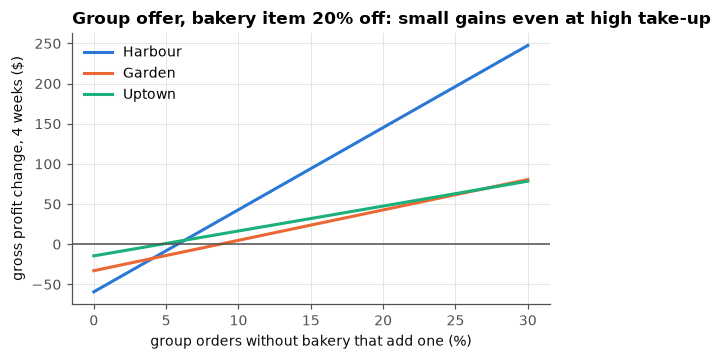

In [11]:
fig, ax = plt.subplots(figsize=(5.6, 3.2))
for br in BRANCHES:
    s = sc[sc.branch == br]
    ax.plot(s.takeup * 100, s.profit_change, color=BRANCH_COLORS[br], label=br)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xlabel("group orders without bakery that add one (%)"); ax.set_ylabel("gross profit change, 4 weeks ($)")
ax.set_title("Group offer, bakery item 20% off: small gains even at high take-up")
ax.legend(); save(fig, "09_group_offer_profit"); plt.show()

## 6. A pilot Stories can run

**Metric:** the share of group baskets (two or more drinks) that contain a bakery item. If a share `u` of group baskets without bakery add one, this rises by about `u x (1 - current share)`.

**Fairness check:** without any offer, is that share stable month to month? If so, comparing the offer weeks with the weeks just before is a fair test.

In [12]:
gm = txn[txn.group]
print("share of group baskets with bakery, by month:",
      gm.cats.map(lambda s: ADDON in s).groupby(gm.date.dt.to_period("M")).mean().round(3).to_dict())

rows = []
for weeks in [2, 4]:
    n = (pool.sum(axis=1) * months_test * scale).sum() * weeks / 4
    p0 = pool.already.sum() / pool.sum(axis=1).sum()
    mde = (norm.ppf(0.975) + norm.ppf(0.8)) * np.sqrt(2 * p0 * (1 - p0) / n)
    rows.append(dict(weeks=weeks, group_baskets=round(n), share_with_bakery_now=p0,
                     smallest_detectable_takeup=mde / (1 - p0),
                     breakeven_takeup_worst_branch=be[be.discount == D].breakeven_takeup.max()))
pd.DataFrame(rows).round(3)

share of group baskets with bakery, by month: {Period('2026-01', 'M'): 0.121, Period('2026-02', 'M'): 0.104, Period('2026-03', 'M'): 0.112, Period('2026-04', 'M'): 0.119, Period('2026-05', 'M'): 0.103, Period('2026-06', 'M'): 0.113}


,weeks,group_baskets,share_with_bakery_now,smallest_detectable_takeup,breakeven_takeup_worst_branch
0,2,575,0.111,0.059,0.087
1,4,1150,0.111,0.041,0.087


## 7. Recommendation

**Do not launch a group offer yet. First, run a free check on Stories' real till data.**

**Measured (from the data):**
- Two-drink baskets have food far less often than solo baskets (23% against 47%), but most of that gap comes from the dataset's 3-line limit. With room on the receipt, group baskets carry food about as often as one solo customer (49%), not two (about 72%).
- Group orders are 16 to 18% of baskets at every hour, day, branch and order type, so they cannot be targeted by time; the offer would be triggered at the till by two or more drinks.
- With a bakery item at 20% off, the offer breaks even when **5 to 9% of group orders without bakery add one** (Uptown lowest, Garden highest). At 30% off that rises to 9 to 20%, and at 50% off Garden loses money on every sale.

**Estimated (depends on take-up, which is unknown):**

| Group orders without bakery that add one | 0% | 5% | 10% | 20% |
|---|---|---|---|---|
| Gross profit change, 4 weeks, all branches, 20% off | -$107 | -$21 | +$65 | +$236 |
| As % of projected gross profit ($36,913) | -0.3% | -0.1% | +0.2% | +0.6% |

At 10 to 20% take-up that is roughly **$800 to $3,000 a year**, well below the bundle offer in `06_bundle_offers.ipynb` ($6,000 to $20,000).

**The free check:** in a real till export, take baskets with two or more drinks and measure how often they include food. If it is well below the roughly 70% expected for two separate customers, groups really do skip food, and a 4-week pilot at 20% off is worth running: it can detect a take-up of about 4%, below every branch's break-even, and its worst case costs about $110 of gross profit. If real group baskets carry food about as often as two solo customers, drop the idea.

**Priority:** run this after the bundle pilot, not alongside it. The two offers overlap on bakery and would blur each other's results.

## 8. What could change this

- **Party size is a guess.** Two drinks may be one person, for example a coffee and a water. If many group baskets are really solo customers, the food gap is smaller than it looks and take-up will be lower.
- **The data looks generated.** No basket has more than 3 lines, and group orders are equally common at every hour and day. Real group orders would probably cluster on evenings, weekends and dine-in. The food gap may be a feature of how the data was built, which is why the result is a pilot and not a rollout.
- **Overlap with the bundle offer.** A group buying two matcha drinks and a croissant could qualify for both this offer and the bakery + matcha bundle in `06_bundle_offers.ipynb`. *Assumption:* one discount per basket, the larger one. If both pilots run together, they must be measured on separate baskets or in separate weeks.
- **Costs are standard costs.** If `Unit Cost` leaves out waste or labour, margins are lower and the break-even take-up is higher.
- **Substitution.** A group might take the discounted pastry instead of a more profitable food item. The pilot should track average gross profit per group basket, not only the bakery share.